In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.mixture import GaussianMixture

In [2]:
df = pd.read_csv('SouthGermanCredit.asc', sep=r'\s+')
df.head()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000 non-null   int64
 16  beruf     1000 non-null   int64
 17  pers      1000 non-null   int64
 18  telef     1000 non-null   int64
 19  gastarb   1000 non-null   int64
 20  kredit    1000 non-null   int64
dtypes: int64(21)
memory usage: 164.2 KB


In [4]:
# Проверяем пропуски
df.isna().sum()

laufkont    0
laufzeit    0
moral       0
verw        0
hoehe       0
sparkont    0
beszeit     0
rate        0
famges      0
buerge      0
wohnzeit    0
verm        0
alter       0
weitkred    0
wohn        0
bishkred    0
beruf       0
pers        0
telef       0
gastarb     0
kredit      0
dtype: int64

In [5]:
# Проверяем полные повторы строк
df.duplicated().sum()

np.int64(0)

In [6]:
# Изучаем диапазоны количественных признаков
numeric_cols = ['laufzeit', 'hoehe', 'alter']
df[numeric_cols].describe()

,laufzeit,hoehe,alter
count,1000.000000,1000.00000,1000.00000
mean,20.903000,3271.24800,35.54200
std,12.058814,2822.75176,11.35267
min,4.000000,250.00000,19.00000
25%,12.000000,1365.50000,27.00000
50%,18.000000,2319.50000,33.00000
75%,24.000000,3972.25000,42.00000
max,72.000000,18424.00000,75.00000


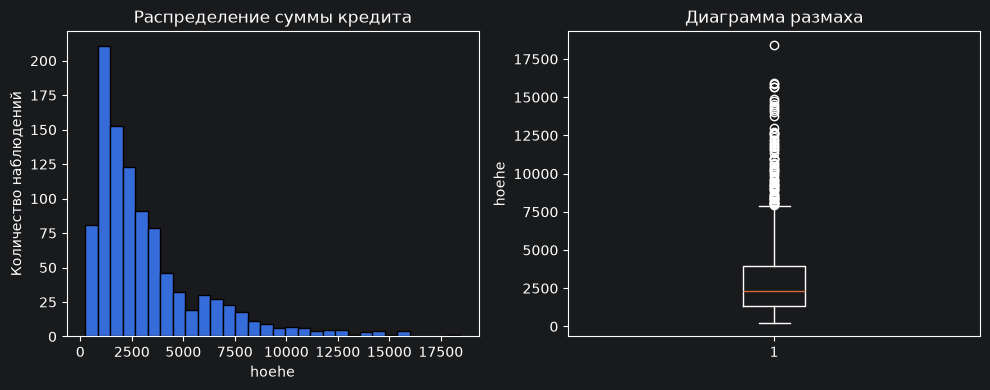

In [7]:
# Строим график, хочу посмотреть на распределение суммы кредита
# Вижу что фича hoehe имеет правостороннюю асимметрию:
# mean - 3271.25, 50% - 2319.5
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(df['hoehe'], bins=30, edgecolor='black')
ax[0].set_xlabel('hoehe')
ax[0].set_ylabel('Количество наблюдений')
ax[0].set_title('Распределение суммы кредита')

ax[1].boxplot(df['hoehe'])
ax[1].set_ylabel('hoehe')
ax[1].set_title('Диаграмма размаха')

plt.tight_layout()
plt.show()

In [8]:
# Делим датасет, 60/20/20
x = df.drop(columns='kredit')
y = df['kredit']

x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.25, random_state=42
)

print(x_train.shape, x_val.shape, x_test.shape)

(600, 20) (200, 20) (200, 20)


In [9]:
# Создаем новую фичу, логарифм hoehe, чтобы сжать диапазон больших значений
x_train['hoehe_log'] = np.log1p(x_train['hoehe'])
x_val['hoehe_log'] = np.log1p(x_val['hoehe'])
x_test['hoehe_log'] = np.log1p(x_test['hoehe'])

In [10]:
# Масштабируем и кодируем, обучаем только на train
numeric_cols = ['laufzeit', 'alter', 'hoehe_log']

categorical_cols = x_train.columns.drop(
    numeric_cols + ['hoehe']
).tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ), categorical_cols)
])

x_train_ready = preprocessor.fit_transform(x_train)
x_val_ready = preprocessor.transform(x_val)
x_test_ready = preprocessor.transform(x_test)

print(x_train_ready.shape, x_val_ready.shape, x_test_ready.shape)

(600, 71) (200, 71) (200, 71)


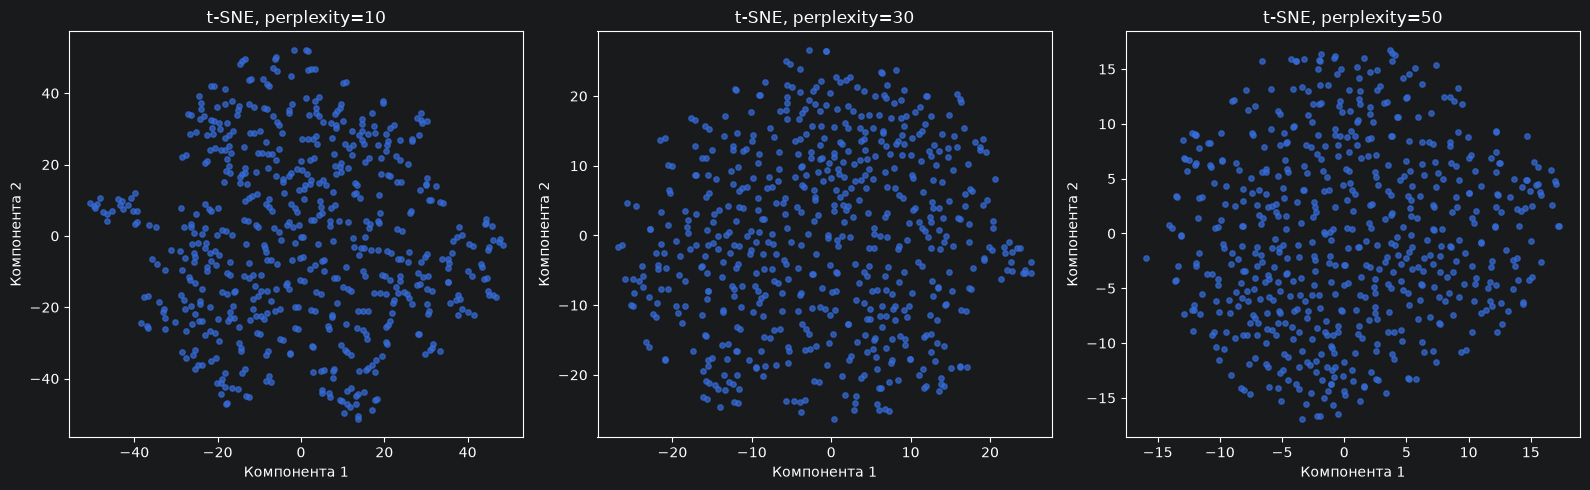

In [11]:
# Сравниваем двумерные представления при разных perplexity
# Я вижу что при разных perplexity оно не показывает устойчивые и выраженные группы
perplexities = [10, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, perplexity in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init='pca',
        learning_rate='auto',
        random_state=42
    )
    embedding = tsne.fit_transform(x_train_ready)

    ax.scatter(embedding[:, 0], embedding[:, 1], s=15, alpha=0.7)
    ax.set_title(f't-SNE, perplexity={perplexity}')
    ax.set_xlabel('Компонента 1')
    ax.set_ylabel('Компонента 2')

plt.tight_layout()
plt.show()

In [12]:
# Обучаем модель на подготовленных фичах
baseline_kmeans = KMeans(random_state=42)
baseline_kmeans.fit(x_train_ready)

baseline_y_kmeans = baseline_kmeans.predict(x_val_ready)

print(f'Число кластеров на валид: {np.unique(baseline_y_kmeans).size}\n'
      f'Silhouette на валид: {silhouette_score(x_val_ready, baseline_y_kmeans)}')

Число кластеров на валид: 8
Silhouette на валид: 0.03949893906479271


In [13]:
# Подбираем число кластеров по silhouette на валидации
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(x_train_ready)
    y_val_pred = model.predict(x_val_ready)

    score = silhouette_score(x_val_ready, y_val_pred)
    results.append({'k': k, 'silhouette': score})

kmeans_results = pd.DataFrame(results)
kmeans_results.sort_values('silhouette', ascending=False)

,k,silhouette
0,2,0.107579
1,3,0.082726
2,4,0.068557
3,5,0.056291
4,6,0.048686
5,7,0.046441
7,9,0.041319
6,8,0.041100
8,10,0.032146


In [14]:
# Выбираем лучший k на валидации
best_k = int(
    kmeans_results.loc[kmeans_results['silhouette'].idxmax(), 'k']
)

best_kmeans = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=42
)
best_kmeans.fit(x_train_ready)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 71)","[[-0

In [15]:
# Теперь обучаем вторую модель
baseline_gmm = GaussianMixture(
    n_components=best_k,
    random_state=42
)
baseline_gmm.fit(x_train_ready)

baseline_y_qmm = baseline_gmm.predict(x_val_ready)

print(f'Модель сошлась: {baseline_gmm.converged_}\n'
      f'Число кластеров на валид: {np.unique(baseline_y_qmm).size}\n'
      f'Silhouette на валид: {silhouette_score(x_val_ready, baseline_y_qmm)}')

Модель сошлась: True
Число кластеров на валид: 2
Silhouette на валид: 0.009696297214644885


In [16]:
# Подбираем гиперпараметры для GaussianMixture по валидации
gmm_results = []

for k in range(2, 11):
    for covariance in ['full', 'tied', 'diag', 'spherical']:
        model = GaussianMixture(
            n_components=k,
            covariance_type=covariance,
            n_init=5,
            random_state=42
        )
        model.fit(x_train_ready)
        y_val_pred = model.predict(x_val_ready)

        n_pred = np.unique(y_val_pred).size

        # Оцениваем только сошедшиеся модели с допустимым числом групп
        score = np.nan
        if model.converged_ and 2 <= n_pred < len(y_val_pred):
            score = silhouette_score(x_val_ready, y_val_pred)

        gmm_results.append({
            'k': k,
            'covariance_type': covariance,
            'silhouette': score,
            'converged': model.converged_
        })

gmm_results_df = pd.DataFrame(gmm_results)
gmm_results_df.sort_values(
    'silhouette', ascending=False
).head(10)

,k,covariance_type,silhouette,converged
3,2,spherical,0.107579,True
7,3,spherical,0.079718,True
11,4,spherical,0.070815,True
19,6,spherical,0.047058,True
15,5,spherical,0.045532,True
31,9,spherical,0.042996,True
23,7,spherical,0.041450,True
27,8,spherical,0.039989,True
5,3,tied,0.038542,True
35,10,spherical,0.038498,True


In [17]:
# Выбираем лучшие параметры GaussianMixture по валидации
best_gmm_row = gmm_results_df.loc[
    gmm_results_df['silhouette'].idxmax()
]

best_gmm = GaussianMixture(
    n_components=int(best_gmm_row['k']),
    covariance_type=best_gmm_row['covariance_type'],
    n_init=5,
    random_state=42
)
best_gmm.fit(x_train_ready)

,"n_components n_components: int, default=1The number of mixture components.",2
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'spherical'
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [18]:
# Итоговая оценка базовых и бест моделей на тест
models = {
    'KMeans baseline': baseline_kmeans,
    'KMeans tuned': best_kmeans,
    'GMM initial (2 components)': baseline_gmm,
    'GMM tuned': best_gmm
}

test_results = []
test_predictions = {}

for name, model in models.items():
    labels = model.predict(x_test_ready)
    test_predictions[name] = labels

    n_labels = np.unique(labels).size

    score = np.nan
    if 2 <= n_labels < len(labels):
        score = silhouette_score(x_test_ready, labels)

    test_results.append({
        'Model': name,
        'Clusters on test': n_labels,
        'Silhouette': score
    })

comparison = pd.DataFrame(test_results)
comparison

,Model,Clusters on test,Silhouette
0,KMeans baseline,8,0.035571
1,KMeans tuned,2,0.101613
2,GMM initial (2 components),2,0.016458
3,GMM tuned,2,0.101613


In [19]:
# Сравниваем разбиения двух бест моделей на тест
ari = adjusted_rand_score(
    test_predictions['KMeans tuned'],
    test_predictions['GMM tuned']
)

ari

1.0

Визуализация t-SNE не показала чётко отделённых групп и не позволила однозначно определить число кластеров. По silhouette на валидационной выборке среди проверенных вариантов выбраны KMeans с двумя кластерами и GaussianMixture с двумя компонентами и сферическими ковариациями.

На тестовой выборке silhouette составил 0,1016 у обеих настроенных моделей, превысив результаты исходных вариантов: 0,0356 для KMeans и 0,0165 для GaussianMixture. Разбиения настроенных моделей полностью совпали (ARI = 1,0). Однако низкий silhouette указывает на слабую разделённость групп в выбранном пространстве признаков.